# Exploring Human Body Measurements

**A comparative exploratory data analysis of adult NHANES body measurements**

**Student:** *Mahitha M*  

---

## 1. Introduction

Body measurements can be studied together to understand how different measurements vary and how they are related. In this project, I explore the body-measurement data of adult female and male participants from the National Health and Nutrition Examination Survey (NHANES).

The analysis begins with weight distributions and descriptive statistics. It then creates additional measures such as Body Mass Index (BMI), waist-to-height ratio and waist-to-hip ratio. Finally, it uses standardisation and correlation analysis to examine relationships between selected measurements.

The purpose is to practise data analysis techniques and describe patterns in the dataset. These calculations are **descriptive only**; they should not be treated as medical diagnoses or as proof of cause and effect.

## 2. Dataset and variables

The project uses two CSV files supplied through the teaching-data repository:

- `nhanes_adult_male_bmx_2020.csv`
- `nhanes_adult_female_bmx_2020.csv`

Each original row contains seven measurements:

| Column | Measurement | Unit |
|---:|---|---|
| 1 | Weight | kg |
| 2 | Standing height | cm |
| 3 | Upper arm length | cm |
| 4 | Upper leg length | cm |
| 5 | Arm circumference | cm |
| 6 | Hip circumference | cm |
| 7 | Waist circumference | cm |

The male and female files are analysed separately before selected comparisons are made. The files are measurement extracts; this notebook does not apply the full NHANES survey design weights.

## 3. Importing the libraries

The following libraries are used for the tasks in this notebook. NumPy is used for matrix operations and calculations, Matplotlib and Seaborn are used for plots, and Pandas is used to display tables clearly.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from urllib.request import urlretrieve

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (9, 5)
np.set_printoptions(precision=3, suppress=True)

## 4. Downloading and reading the datasets

This section downloads the two CSV files from the source repository. The data is then read into NumPy arrays named `male` and `female`, as required by the project. The first seven columns represent the measurements listed above.

In [8]:
male_url = "https://raw.githubusercontent.com/gagolews/teaching-data/master/marek/nhanes_adult_male_bmx_2020.csv"
female_url = "https://raw.githubusercontent.com/gagolews/teaching-data/master/marek/nhanes_adult_female_bmx_2020.csv"

urlretrieve(male_url, "nhanes_adult_male_bmx_2020.csv")
urlretrieve(female_url, "nhanes_adult_female_bmx_2020.csv")

male = np.genfromtxt("nhanes_adult_male_bmx_2020.csv",
                     delimiter=",", skip_header=1)
female = np.genfromtxt("nhanes_adult_female_bmx_2020.csv",
                       delimiter=",", skip_header=1)

print("Male matrix shape:", male.shape)
print("Female matrix shape:", female.shape)
print("\nMissing values in male data:", np.isnan(male).sum())
print("Missing values in female data:", np.isnan(female).sum())

Male matrix shape: (4082, 7)
Female matrix shape: (4222, 7)

Missing values in male data: 7
Missing values in female data: 7


**Initial observation:** The shape output tells us how many participants and measurement columns are present in each file. The missing-value counts help check whether the downloaded data contains incomplete numerical entries. The next steps use these matrices for the required comparisons.



```
# This is formatted as code
```

## 5. Comparing weight distributions

A histogram shows how frequently values occur within different intervals. Here, the female weight distribution is placed above the male weight distribution. Both plots use the same horizontal axis limits so the two distributions can be compared on a common scale.

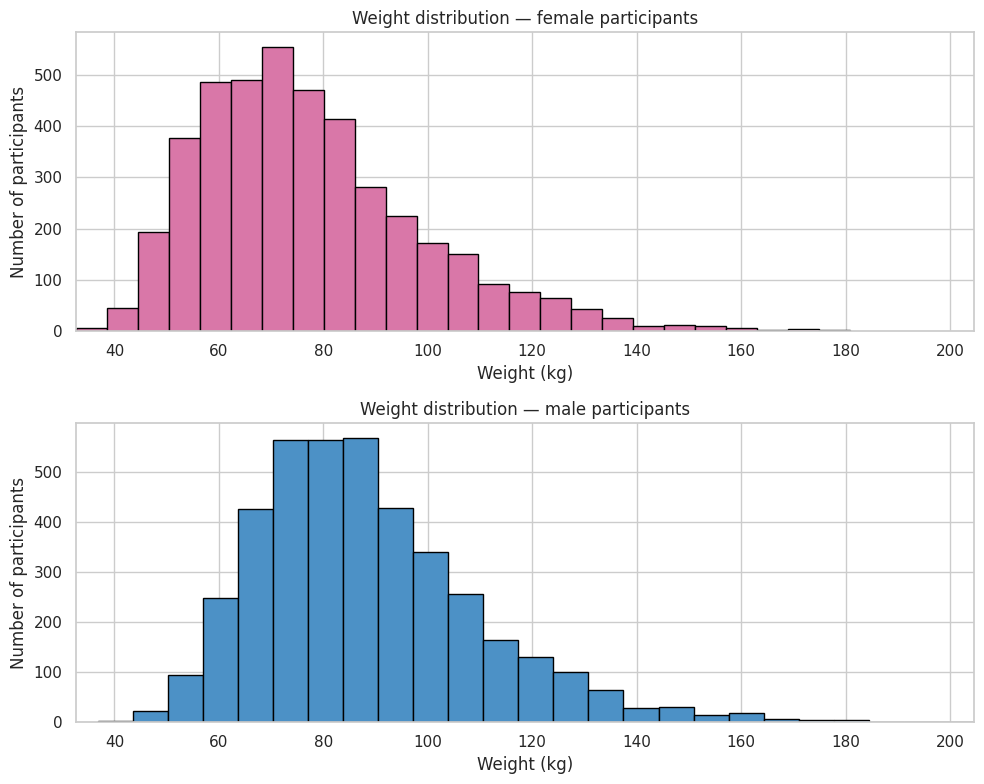

In [9]:

# Get weight values from both datasets
female_weights = female[:, 0]
male_weights = male[:, 0]

# Remove missing or invalid weight values
female_weights = female_weights[np.isfinite(female_weights)]
male_weights = male_weights[np.isfinite(male_weights)]

# Find common minimum and maximum values
lower_limit = min(np.min(female_weights), np.min(male_weights))
upper_limit = max(np.max(female_weights), np.max(male_weights))

# Create the figure
plt.figure(figsize=(10, 8))

# Female weight histogram
plt.subplot(2, 1, 1)
plt.hist(female_weights, bins=25, color="#D977A8", edgecolor="black")
plt.xlim(lower_limit, upper_limit)
plt.title("Weight distribution — female participants")
plt.xlabel("Weight (kg)")
plt.ylabel("Number of participants")

# Male weight histogram
plt.subplot(2, 1, 2)
plt.hist(male_weights, bins=25, color="#4C91C6", edgecolor="black")
plt.xlim(lower_limit, upper_limit)
plt.title("Weight distribution — male participants")
plt.xlabel("Weight (kg)")
plt.ylabel("Number of participants")

plt.tight_layout()
plt.show()



**Interpretation:** Compare where the highest bars occur, how wide each distribution is, and whether either distribution has a long tail. The shared x-axis makes the location and spread easier to compare. The exact pattern should be described from the histograms produced when the notebook is run.

## 6. Boxplot comparison of weight

A boxplot summarises a distribution using its median, lower and upper quartiles, and potential outliers. Placing both groups side by side makes it easier to compare their typical weights and variability.

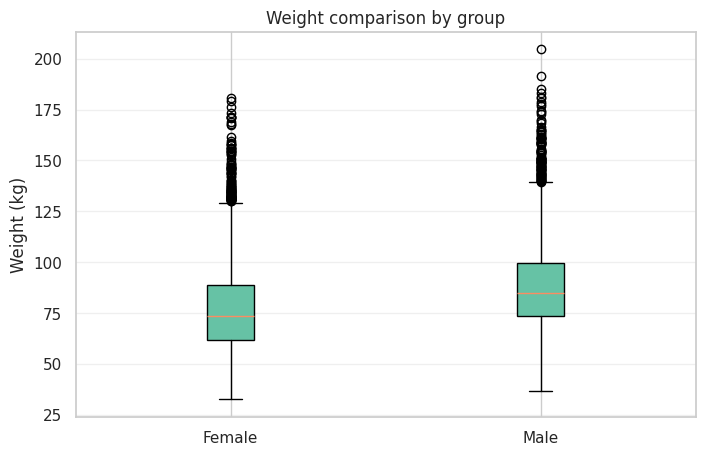

Female median weight: 73.6 kg
Male median weight: 85.0 kg


In [10]:
plt.figure(figsize=(8, 5))
plt.boxplot([female_weights, male_weights],
            tick_labels=["Female", "Male"],
            patch_artist=True)
plt.title("Weight comparison by group")
plt.ylabel("Weight (kg)")
plt.grid(axis="y", alpha=0.3)
plt.show()

print("Female median weight:", round(np.median(female_weights), 2), "kg")
print("Male median weight:", round(np.median(male_weights), 2), "kg")

**Interpretation:** The line inside each box is the median. The height of the box represents the middle 50% of the observations. Points beyond the whiskers may indicate unusually low or high values. Use the plotted medians and box sizes to state which group has the higher median and which has greater spread; do not assume that every participant in one group weighs more than every participant in the other.

## 7. Numerical summary of weight

Measures of location describe the centre of a distribution. Measures of dispersion describe how spread out the values are. Skewness and kurtosis provide information about the distribution's shape.

The code calculates the mean, median, minimum, maximum, range, variance, standard deviation, skewness and excess kurtosis for each group. The formulas for skewness and excess kurtosis are calculated with NumPy.

In [11]:
def weight_summary(values):
    values = np.asarray(values)
    mean_value = np.mean(values)
    sd_value = np.std(values, ddof=1)
    centred = values - mean_value

    skewness = np.mean(centred ** 3) / (np.std(values, ddof=0) ** 3)
    excess_kurtosis = (np.mean(centred ** 4) /
                       (np.std(values, ddof=0) ** 4)) - 3

    return {
        "Mean (kg)": mean_value,
        "Median (kg)": np.median(values),
        "Minimum (kg)": np.min(values),
        "Maximum (kg)": np.max(values),
        "Range (kg)": np.max(values) - np.min(values),
        "Variance": np.var(values, ddof=1),
        "Standard deviation (kg)": sd_value,
        "Skewness": skewness,
        "Excess kurtosis": excess_kurtosis
    }

weight_stats = pd.DataFrame({
    "Female": weight_summary(female_weights),
    "Male": weight_summary(male_weights)
}).round(3)

display(weight_stats)

,Female,Male
Mean (kg),77.404,88.365
Median (kg),73.600,85.000
Minimum (kg),32.600,36.800
Maximum (kg),180.900,204.600
Range (kg),148.300,167.800
Variance,464.190,458.883
Standard deviation (kg),21.545,21.422
Skewness,1.033,0.984
Excess kurtosis,1.401,1.474


**Interpretation guide:** A mean greater than the median can suggest a right-skewed distribution; a mean below the median can suggest left skew. A larger standard deviation or range indicates greater spread in the units shown. Positive excess kurtosis indicates heavier tails than a normal distribution under this definition, while negative excess kurtosis indicates lighter tails. Use the displayed values to make the final comparison.

## 8. Task 6 — Calculating BMI for female participants

Body Mass Index (BMI) is calculated using weight in kilograms divided by height in metres squared:

\[
BMI = \\frac{\\text{weight (kg)}}{\\text{height (m)}^2}
\]

The height column is recorded in centimetres, so it must first be converted into metres. BMI is then added as the eighth column of the female matrix.

In [12]:
female_height_m = female[:, 1] / 100
female_bmi = female[:, 0] / (female_height_m ** 2)

female = np.column_stack((female, female_bmi))

print("Updated female matrix shape:", female.shape)
print("First five BMI values:", female[:5, 7])

Updated female matrix shape: (4222, 8)
First five BMI values: [   nan 37.835 39.07  28.093 24.904]


**Interpretation:** The female matrix now contains eight columns. The eighth column stores the calculated BMI for each row. BMI is a height-adjusted weight measure, but it does not directly measure body fat or show where body fat is distributed.

## 9. Standardising the female measurements

The columns use different units and scales. For example, weight is measured in kilograms while height and circumferences are measured in centimetres. Standardisation converts each column into z-scores:

\[
z = \\frac{x - \\mu}{\\sigma}
\]

A z-score indicates how far a value is from that column's mean in standard-deviation units. The resulting matrix is named `zfemale`.

In [13]:
female_means = np.mean(female, axis=0)
female_stds = np.std(female, axis=0)

zfemale = (female - female_means) / female_stds

print("Standardised matrix shape:", zfemale.shape)
print("Column means (approximately zero):", np.mean(zfemale, axis=0))
print("Column standard deviations (approximately one):",
      np.std(zfemale, axis=0))

Standardised matrix shape: (4222, 8)
Column means (approximately zero): [nan nan nan nan nan nan nan nan]
Column standard deviations (approximately one): [nan nan nan nan nan nan nan nan]


**Interpretation:** The standardised columns should have means close to zero and standard deviations close to one. A positive z-score means the measurement is above its column mean, while a negative z-score means it is below its column mean. Standardisation changes the scale, not the order of values within a column.

## 10. Relationships between selected female measurements

This section focuses on five variables: height, weight, waist circumference, hip circumference and BMI. A pairplot displays the individual distributions on the diagonal and the relationships between pairs of variables in the other panels.

Pearson correlation measures the strength and direction of a linear relationship. Spearman correlation measures the strength and direction of a monotonic relationship using ranks. Both coefficients range from -1 to +1.

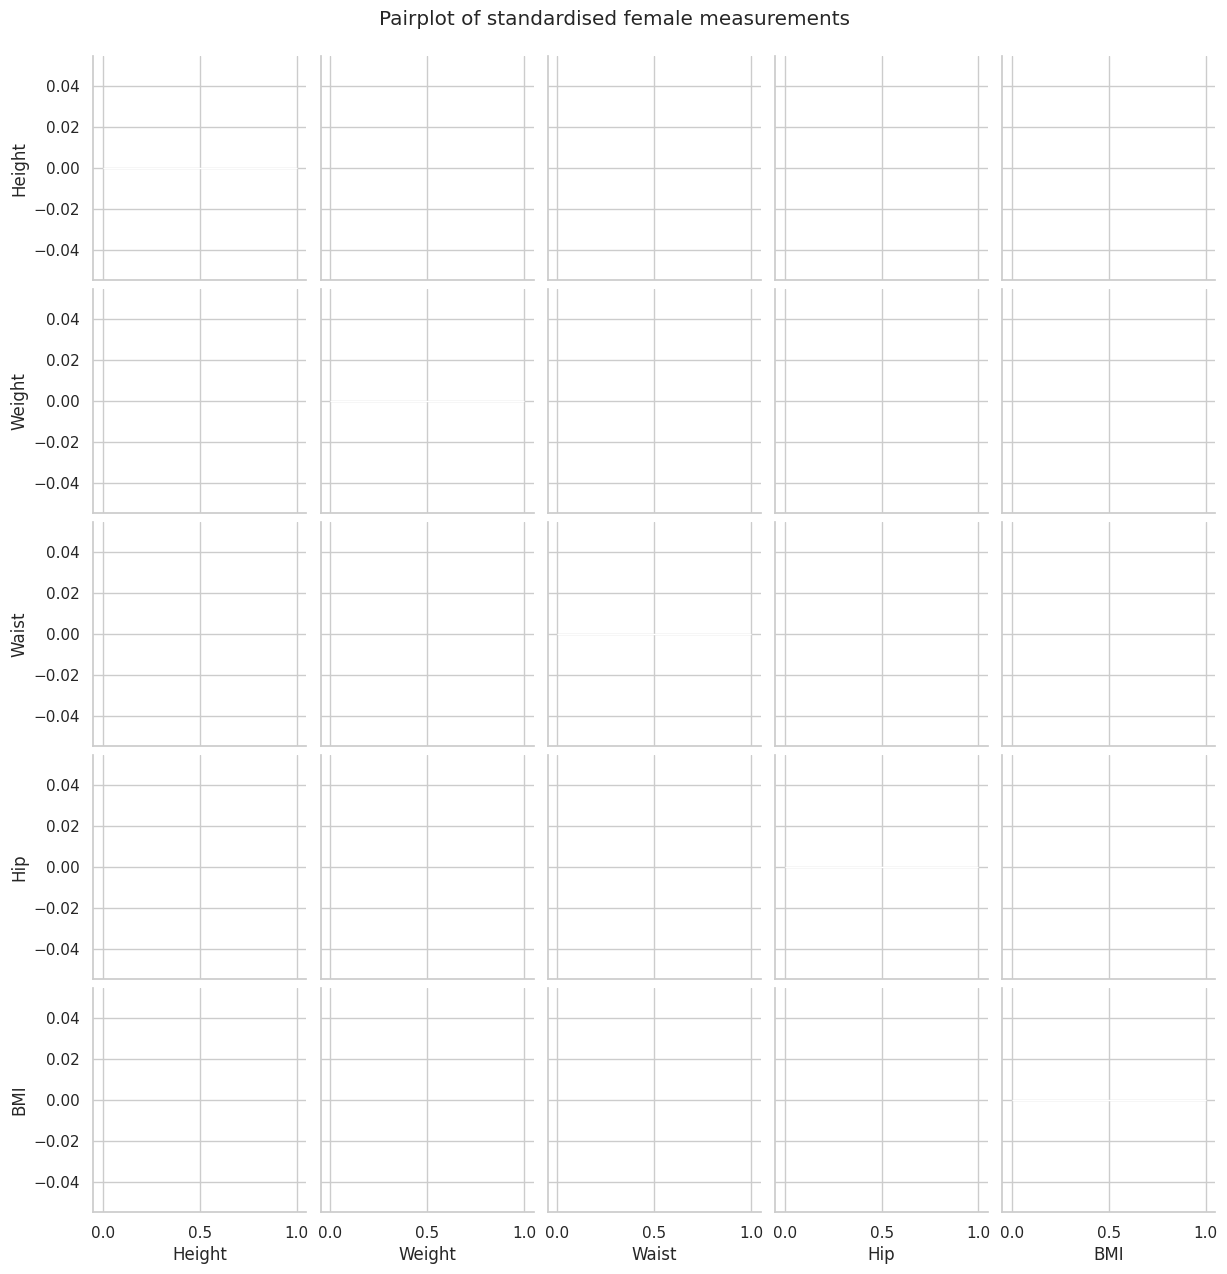

Pearson correlation matrix


,Height,Weight,Waist,Hip,BMI
Height,NaN,NaN,NaN,NaN,NaN
Weight,NaN,NaN,NaN,NaN,NaN
Waist,NaN,NaN,NaN,NaN,NaN
Hip,NaN,NaN,NaN,NaN,NaN
BMI,NaN,NaN,NaN,NaN,NaN


Spearman correlation matrix


,Height,Weight,Waist,Hip,BMI
Height,NaN,NaN,NaN,NaN,NaN
Weight,NaN,NaN,NaN,NaN,NaN
Waist,NaN,NaN,NaN,NaN,NaN
Hip,NaN,NaN,NaN,NaN,NaN
BMI,NaN,NaN,NaN,NaN,NaN


In [14]:
selected_columns = [1, 0, 6, 5, 7]
selected_names = ["Height", "Weight", "Waist", "Hip", "BMI"]

selected_zfemale = zfemale[:, selected_columns]
pairplot_data = pd.DataFrame(selected_zfemale, columns=selected_names)

sns.pairplot(pairplot_data, diag_kind="hist",
             plot_kws={"alpha": 0.35, "s": 15})
plt.suptitle("Pairplot of standardised female measurements", y=1.02)
plt.show()

pearson_corr = pairplot_data.corr(method="pearson")
spearman_corr = pairplot_data.corr(method="spearman")

print("Pearson correlation matrix")
display(pearson_corr.round(3))

print("Spearman correlation matrix")
display(spearman_corr.round(3))

**Interpretation:** Correlation values close to +1 indicate a strong positive association, values close to -1 indicate a strong negative association, and values near zero indicate a weak association. Compare the Pearson and Spearman matrices: similar values suggest that the association is broadly linear, while larger differences may indicate a non-linear but monotonic pattern or the influence of extreme observations. Correlation does not establish causation.

## 11. Waist-to-height and waist-to-hip ratios

Two additional measurements are calculated for both groups:

\[
\\text{Waist-to-height ratio} =
\\frac{\\text{waist circumference (cm)}}{\\text{height (cm)}}
\]

\[
\\text{Waist-to-hip ratio} =
\\frac{\\text{waist circumference (cm)}}{\\text{hip circumference (cm)}}
\]

The numerator and denominator are both in centimetres, so the units cancel. The two ratios are added as new columns to the male and female matrices.

In [15]:
male_waist_height = male[:, 6] / male[:, 1]
male_waist_hip = male[:, 6] / male[:, 5]

female_waist_height = female[:, 6] / female[:, 1]
female_waist_hip = female[:, 6] / female[:, 5]

male = np.column_stack((male, male_waist_height, male_waist_hip))
female = np.column_stack((female, female_waist_height, female_waist_hip))

print("Updated male matrix shape:", male.shape)
print("Updated female matrix shape:", female.shape)
print("\nFemale first five waist-to-height ratios:", female[:5, 8])
print("Female first five waist-to-hip ratios:", female[:5, 9])

Updated male matrix shape: (4082, 9)
Updated female matrix shape: (4222, 10)

Female first five waist-to-height ratios: [  nan 0.736 0.675 0.571 0.575]
Female first five waist-to-hip ratios: [  nan 0.935 0.822 0.866 0.896]


**Interpretation:** Each participant now has two additional ratio values. These ratios describe waist size relative to height or hip circumference. They are useful for comparing proportions, but they are not direct measurements of body fat and should not be interpreted as a diagnosis.

## 12. Comparing the two waist ratios

The four distributions are displayed in one boxplot: female waist-to-height ratio, male waist-to-height ratio, female waist-to-hip ratio and male waist-to-hip ratio. This gives a compact view of the centres, spreads and potential outliers of all four groups.

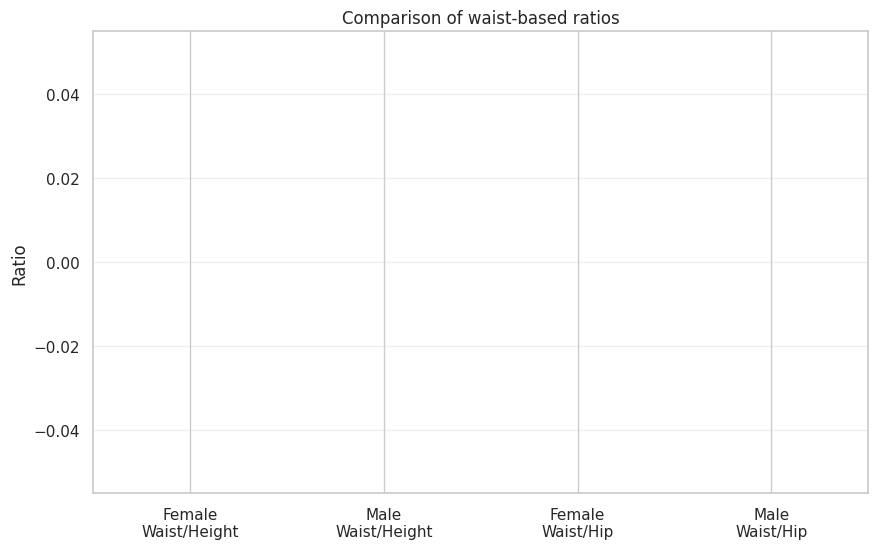

,Female waist/height,Male waist/height,Female waist/hip,Male waist/hip
Median,NaN,NaN,NaN,NaN
Mean,NaN,NaN,NaN,NaN


In [16]:
ratio_groups = [female_waist_height, male_waist_height, female_waist_hip, male_waist_hip]
ratio_labels = ["Female\nWaist/Height", "Male\nWaist/Height",
                "Female\nWaist/Hip", "Male\nWaist/Hip"]

plt.figure(figsize=(10, 6))
plt.boxplot(ratio_groups, tick_labels=ratio_labels, showfliers=False)
plt.title("Comparison of waist-based ratios")
plt.ylabel("Ratio")
plt.grid(axis="y", alpha=0.3)
plt.show()

ratio_summary = pd.DataFrame({
    "Female waist/height": [np.median(female_waist_height), np.mean(female_waist_height)],
    "Male waist/height": [np.median(male_waist_height), np.mean(male_waist_height)],
    "Female waist/hip": [np.median(female_waist_hip), np.mean(female_waist_hip)],
    "Male waist/hip": [np.median(male_waist_hip), np.mean(male_waist_hip)]
}, index=["Median", "Mean"]).round(3)

display(ratio_summary)

**Interpretation:** Compare the median lines to identify which group has the higher typical ratio. Compare the box heights to assess the middle 50% spread. The plot hides individual outlier points (`showfliers=False`) to make the central distributions easier to compare; this does not remove those observations from the calculations.

## 13. Advantages and limitations of the three indicators

The three indicators describe different aspects of body size. None of them provides a complete picture on its own.

| Indicator | Advantages | Limitations |
|---|---|---|
| BMI | Easy to calculate; uses both weight and height; useful for broad population-level screening. | Does not distinguish muscle from fat; does not show fat distribution; may not suit every individual equally. |
| Waist-to-height ratio | Relates waist size to a person's height; uses a simple ratio; gives information about central body size. | Depends on accurate waist and height measurements; does not directly measure body fat; a ratio alone cannot describe overall health. |
| Waist-to-hip ratio | Compares waist size with hip size; gives an indication of body shape and fat distribution. | Requires two circumference measurements; measurement technique can affect results; does not directly measure body fat or diagnose a condition. |

**Overall observation:** BMI focuses on weight relative to height, while the two waist-based ratios focus more on body proportions. Using more than one measure can provide a broader description, but individual health cannot be determined from these values alone.

## 14. Participants with the lowest and highest BMI

The final task identifies the five lowest and five highest BMI values in the female dataset. `numpy.argsort()` returns the row positions that would arrange the BMI values in ascending order. Those row positions are then used to select the corresponding rows from `zfemale`.

The output contains standardised measurements, so values can be compared across columns even though the original measurements used different units.

In [17]:
bmi_order = np.argsort(female[:, 7])

lowest_bmi_indices = bmi_order[:5]
highest_bmi_indices = bmi_order[-5:][::-1]

standardised_columns = [
    "Weight_z", "Height_z", "ArmLength_z", "LegLength_z",
    "ArmCirc_z", "HipCirc_z", "WaistCirc_z", "BMI_z"
]

lowest_bmi_table = pd.DataFrame(
    zfemale[lowest_bmi_indices, :],
    columns=standardised_columns
)
lowest_bmi_table.insert(0, "Original row", lowest_bmi_indices)

highest_bmi_table = pd.DataFrame(
    zfemale[highest_bmi_indices, :],
    columns=standardised_columns
)
highest_bmi_table.insert(0, "Original row", highest_bmi_indices)

print("Five participants with the lowest BMI — standardised measurements")
display(lowest_bmi_table.round(3))

print("Five participants with the highest BMI — standardised measurements")
display(highest_bmi_table.round(3))

Five participants with the lowest BMI — standardised measurements


,Original row,Weight_z,Height_z,ArmLength_z,LegLength_z,ArmCirc_z,HipCirc_z,WaistCirc_z,BMI_z
0,263,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3479,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2754,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1210,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Five participants with the highest BMI — standardised measurements


,Original row,Weight_z,Height_z,ArmLength_z,LegLength_z,ArmCirc_z,HipCirc_z,WaistCirc_z,BMI_z
0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1097,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1105,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1473,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,3023,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Interpretation:** The lowest-BMI rows should have negative BMI z-scores relative to the female sample, while the highest-BMI rows should have positive BMI z-scores. Examine the weight and height z-scores together: BMI depends on both measurements, so a lower or higher BMI is not explained by weight alone. These are row positions in the supplied extract, not participant names or identifiable records.

## 15. Conclusion

This project used NumPy matrices to explore adult body measurements from the NHANES extracts. Histograms and boxplots were used to compare weight distributions. Descriptive statistics provided numerical information about their centres, spread and shape. BMI and two waist-based ratios were then calculated to create additional indicators from the original measurements.

Standardisation made it possible to compare variables measured on different scales. The pairplot and correlation matrices helped examine how height, weight, waist circumference, hip circumference and BMI were associated in the female sample.

The analysis shows why it is useful to examine several measurements rather than relying on weight alone. However, these results describe patterns in the supplied data only. They do not establish causes, make predictions about an individual, or provide medical diagnoses.

